In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("ecommerce_data.csv")
df

,user_id,experiment_date,group,age,device,traffic_source,country,visits,pages_viewed,time_on_site_minutes,purchased,revenue
0,100016,2026-08-01,B,24.0,Mobile,Email,India,3,10,4.52,1,1701.28
1,100050,2026-08-01,A,29.0,Mobile,Paid Search,India,3,11,5.78,0,0.00
2,100076,2026-08-01,B,45.0,Mobile,Social Media,India,4,4,6.90,0,0.00
3,100090,2026-08-01,B,42.0,Mobile,Organic,India,5,7,7.35,0,0.00
4,100155,2026-08-01,B,28.0,Mobile,Paid Search,Australia,1,5,3.72,1,1952.37
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,109671,2026-09-30,A,33.0,Tablet,Referral,India,4,6,5.83,0,0.00
9996,109676,2026-09-30,B,37.0,Mobile,Social Media,India,3,4,5.23,0,0.00
9997,109694,2026-09-30,B,21.0,Mobile,Social Media,India,2,8,5.67,0,0.00
9998,109706,2026-09-30,B,41.0,Desktop,Paid Search,India,5,11,10.59,0,0.00


In [3]:
df.head(5)

,user_id,experiment_date,group,age,device,traffic_source,country,visits,pages_viewed,time_on_site_minutes,purchased,revenue
0,100016,2026-08-01,B,24.0,Mobile,Email,India,3,10,4.52,1,1701.28
1,100050,2026-08-01,A,29.0,Mobile,Paid Search,India,3,11,5.78,0,0.00
2,100076,2026-08-01,B,45.0,Mobile,Social Media,India,4,4,6.90,0,0.00
3,100090,2026-08-01,B,42.0,Mobile,Organic,India,5,7,7.35,0,0.00
4,100155,2026-08-01,B,28.0,Mobile,Paid Search,Australia,1,5,3.72,1,1952.37


In [4]:
df.shape

(10000, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               10000 non-null  int64  
 1   experiment_date       10000 non-null  object 
 2   group                 10000 non-null  object 
 3   age                   9900 non-null   float64
 4   device                10000 non-null  object 
 5   traffic_source        9950 non-null   object 
 6   country               10000 non-null  object 
 7   visits                10000 non-null  int64  
 8   pages_viewed          10000 non-null  int64  
 9   time_on_site_minutes  9920 non-null   float64
 10  purchased             10000 non-null  int64  
 11  revenue               10000 non-null  float64
dtypes: float64(3), int64(4), object(5)
memory usage: 937.6+ KB


In [6]:
df.describe()

,user_id,age,visits,pages_viewed,time_on_site_minutes,purchased,revenue
count,10000.00000,9900.000000,10000.000000,10000.00000,9920.000000,10000.000000,10000.000000
mean,105000.50000,32.184242,4.210200,7.42020,7.552161,0.102600,147.602344
std,2886.89568,8.524988,1.790736,2.85847,2.232145,0.303451,506.267951
min,100001.00000,18.000000,1.000000,1.00000,0.300000,0.000000,0.000000
25%,102500.75000,26.000000,3.000000,5.00000,6.040000,0.000000,0.000000
50%,105000.50000,32.000000,4.000000,7.00000,7.500000,0.000000,0.000000
75%,107500.25000,38.000000,5.000000,9.00000,9.030000,0.000000,0.000000
max,110000.00000,63.000000,12.000000,21.00000,16.070000,1.000000,4774.710000


In [7]:
df.columns

Index(['user_id', 'experiment_date', 'group', 'age', 'device',
       'traffic_source', 'country', 'visits', 'pages_viewed',
       'time_on_site_minutes', 'purchased', 'revenue'],
      dtype='object')

In [8]:
df.isnull().sum()

user_id                   0
experiment_date           0
group                     0
age                     100
device                    0
traffic_source           50
country                   0
visits                    0
pages_viewed              0
time_on_site_minutes     80
purchased                 0
revenue                   0
dtype: int64

In [10]:
df["age"] = df["age"].fillna(df["age"].median())

df["time_on_site_minutes"] = df["time_on_site_minutes"].fillna(
    df["time_on_site_minutes"].median()
)

df["traffic_source"] = df["traffic_source"].fillna(
    df["traffic_source"].mode()[0]
)

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df = df.drop_duplicates()

 A vs B users

In [13]:
df["group"].value_counts()

group
B    5000
A    5000
Name: count, dtype: int64

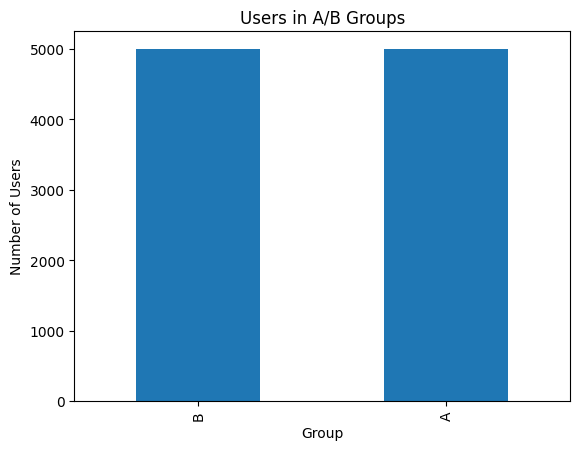

In [14]:
df["group"].value_counts().plot(kind="bar")

plt.title("Users in A/B Groups")
plt.xlabel("Group")
plt.ylabel("Number of Users")
plt.show()

Conversion Rate

In [15]:
conversion = df.groupby("group")["purchased"].mean() * 100

print(conversion)

group
A     8.98
B    11.54
Name: purchased, dtype: float64


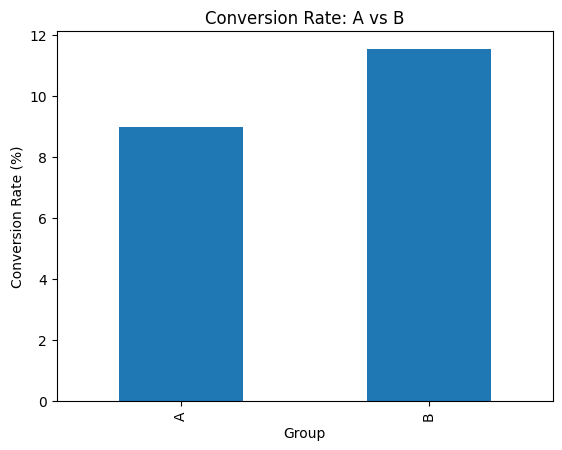

In [16]:
conversion.plot(kind="bar")

plt.title("Conversion Rate: A vs B")
plt.xlabel("Group")
plt.ylabel("Conversion Rate (%)")
plt.show()

Purchase analysis

In [17]:
purchase = df.groupby("group")["purchased"].sum()

print(purchase)

group
A    449
B    577
Name: purchased, dtype: int64


Revenue analysis


Total revenue:

In [18]:
revenue = df.groupby("group")["revenue"].sum()

print(revenue)

group
A    666849.09
B    809174.35
Name: revenue, dtype: float64


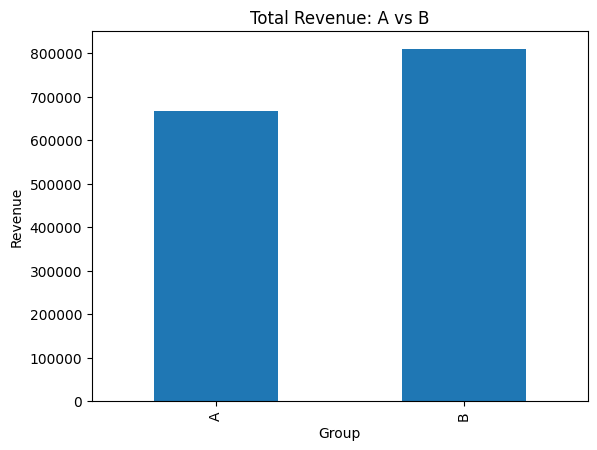

In [32]:
revenue.plot(kind="bar")

plt.title("Total Revenue: A vs B")
plt.xlabel("Group")
plt.ylabel("Revenue")
plt.show()

Average revenue:

In [19]:
avg_revenue = df.groupby("group")["revenue"].mean()

print(avg_revenue)

group
A    133.369818
B    161.834870
Name: revenue, dtype: float64


Device-wise analysis

In [21]:
device_analysis = (
    df.groupby(["device", "group"])["purchased"]
      .mean() * 100
)

print(device_analysis)

device   group
Desktop  A        10.097324
         B        12.174440
Mobile   A         8.612755
         B        11.198428
Tablet   A         6.687898
         B        11.525424
Name: purchased, dtype: float64


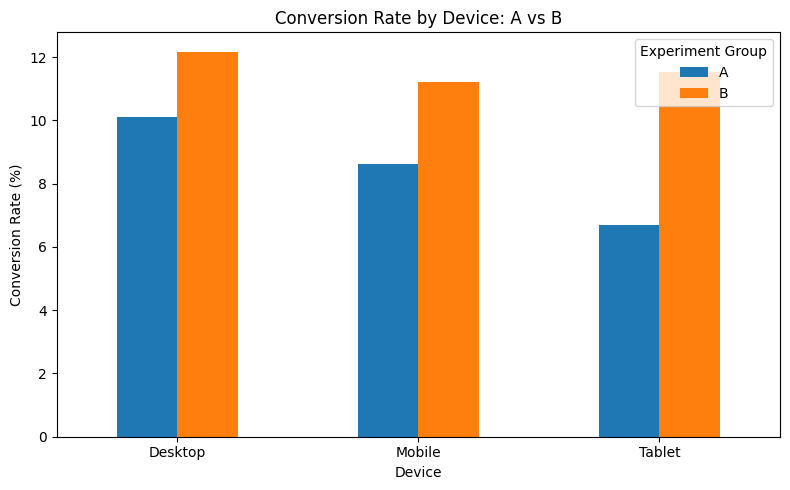

In [34]:

device_analysis = (
    df.groupby(["device", "group"])["purchased"]
      .mean()
      .unstack() * 100
)

device_analysis.plot(kind="bar", figsize=(8, 5))

plt.title("Conversion Rate by Device: A vs B")
plt.xlabel("Device")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Experiment Group")
plt.tight_layout()
plt.show()


Traffic source analysis

In [23]:
source_analysis = (
    df.groupby(["traffic_source", "group"])["purchased"]
      .mean()
      .unstack() * 100
)

print(source_analysis.round(2))

group              A      B
traffic_source             
Direct          7.99  10.53
Email           9.42  12.52
Organic         8.76  11.91
Paid Search     9.55  10.98
Referral        8.40  14.58
Social Media    9.35  10.36


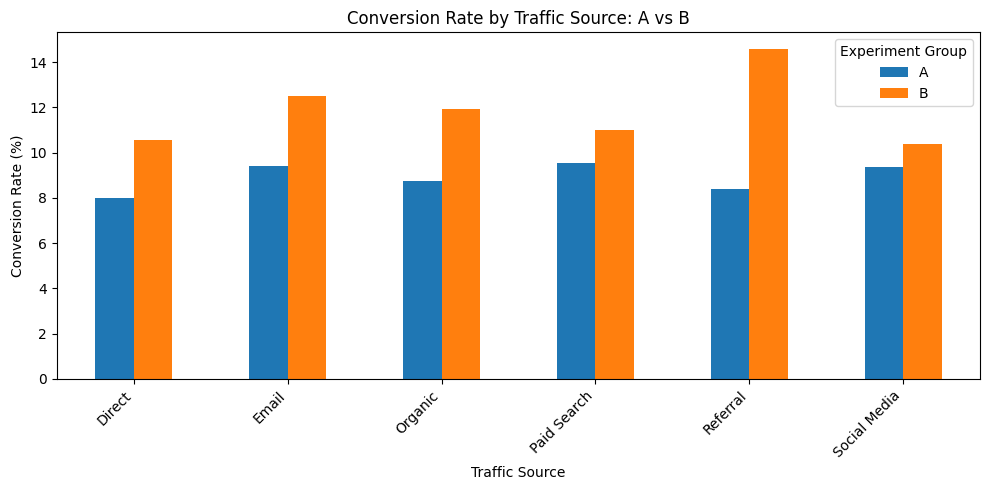

In [33]:

source_analysis = (
    df.groupby(["traffic_source", "group"])["purchased"]
      .mean()
      .unstack() * 100
)

source_analysis.plot(kind="bar", figsize=(10, 5))

plt.title("Conversion Rate by Traffic Source: A vs B")
plt.xlabel("Traffic Source")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Experiment Group")
plt.tight_layout()
plt.show()


Country analysis

In [24]:
country_analysis = (
    df.groupby(["country", "group"])["purchased"]
      .mean()
      .unstack() * 100
)

print(country_analysis.round(2))

group          A      B
country                
Australia   8.60  11.71
Canada     10.72  14.67
India       9.21  11.49
UK          7.94  11.79
USA         8.30  10.14


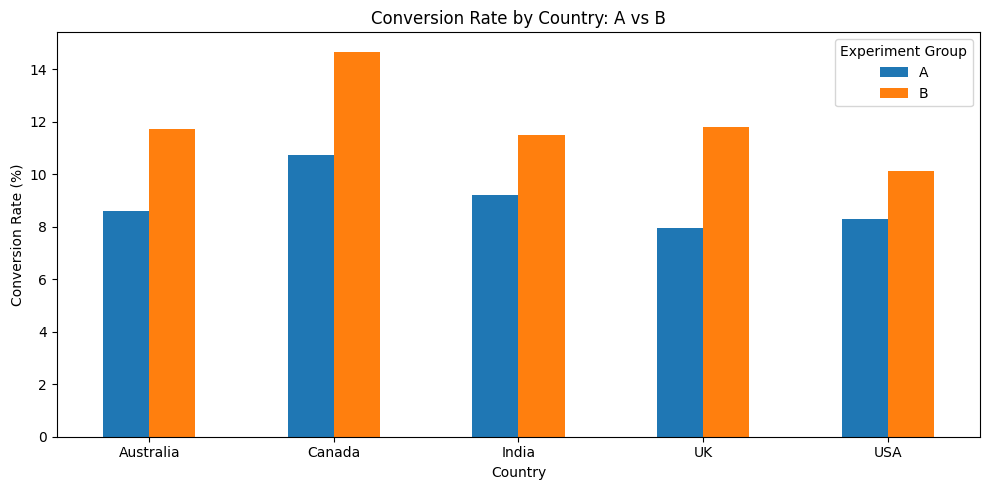

In [31]:

country_analysis = (
    df.groupby(["country", "group"])["purchased"]
      .mean()
      .unstack() * 100
)

country_analysis.plot(kind="bar", figsize=(10, 5))

plt.title("Conversion Rate by Country: A vs B")
plt.xlabel("Country")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Experiment Group")
plt.tight_layout()
plt.show()


Age analysis

In [26]:
bins = [17, 25, 35, 45, 55, 65]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65"]

df["age_group"] = pd.cut(
    df["age"],
    bins=bins,
    labels=labels
)

In [27]:
age_analysis = (
    df.groupby(["age_group", "group"], observed=True)["purchased"]
      .mean()
      .unstack() * 100
)

print(age_analysis.round(2))

group          A      B
age_group              
18-25       8.76  10.63
26-35       9.08  10.84
36-45       9.20  12.87
46-55       7.72  12.93
56-65      14.29  27.78


Daily A/B analysis

In [28]:
df["experiment_date"] = pd.to_datetime(df["experiment_date"])

daily_conversion = (
    df.groupby(["experiment_date", "group"])["purchased"]
      .mean() * 100
)

print(daily_conversion.head())

experiment_date  group
2026-08-01       A         8.139535
                 B        15.151515
2026-08-02       A         9.876543
                 B        13.253012
2026-08-03       A         2.597403
Name: purchased, dtype: float64


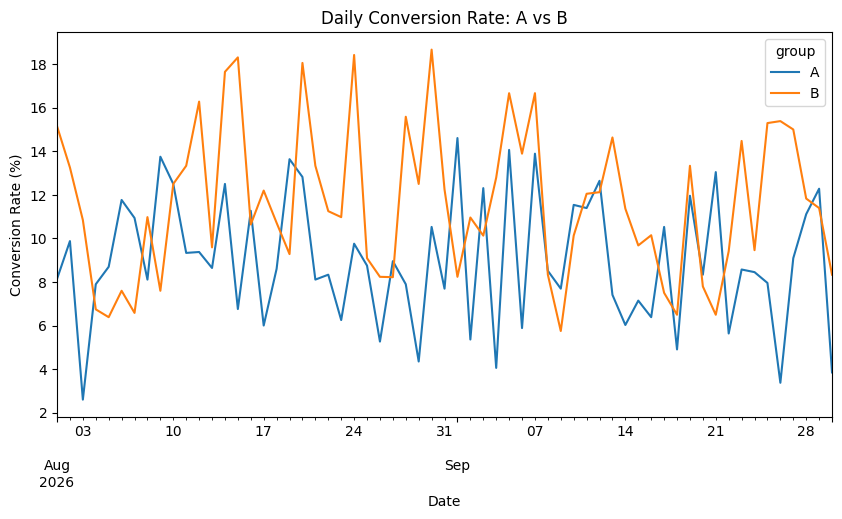

In [29]:
daily_conversion.unstack().plot(figsize=(10,5))

plt.title("Daily Conversion Rate: A vs B")
plt.xlabel("Date")
plt.ylabel("Conversion Rate (%)")
plt.show()

Final Analysis Summary

In [30]:
summary = df.groupby("group").agg(
    users=("user_id", "count"),
    purchases=("purchased", "sum"),
    conversion_rate=("purchased", "mean"),
    total_revenue=("revenue", "sum"),
    average_revenue=("revenue", "mean")
)

summary["conversion_rate"] = summary["conversion_rate"] * 100

summary

,users,purchases,conversion_rate,total_revenue,average_revenue
group,,,,,
A,5000,449,8.98,666849.09,133.369818
B,5000,577,11.54,809174.35,161.834870
